# EcoSort — 02. Análise de resultados e do fluxo integrado

In [1]:
# Ajuste de caminho: permite rodar o notebook a partir de notebooks/ ou da raiz (Colab)
import os, sys
from pathlib import Path
raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(raiz); sys.path.insert(0, str(raiz))
print("Raiz do projeto:", raiz)

Raiz do projeto: <raiz_do_projeto>


## Métricas da visão (conjunto de teste)

In [2]:
import json, pandas as pd
mv = json.load(open('resultados/metricas_visao.json', encoding='utf-8'))
print(f"Acurácia: {mv['acuracia']:.4f} | F1 macro: {mv['f1_macro']:.4f}")
pd.DataFrame(mv['por_classe']).T.round(3)

Acurácia: 0.8684 | F1 macro: 0.8461


,precision,recall,f1-score,support
cardboard,0.929,0.867,0.897,60.0
glass,0.882,0.882,0.882,76.0
metal,0.862,0.903,0.882,62.0
paper,0.885,0.865,0.875,89.0
plastic,0.887,0.863,0.875,73.0
trash,0.600,0.750,0.667,20.0


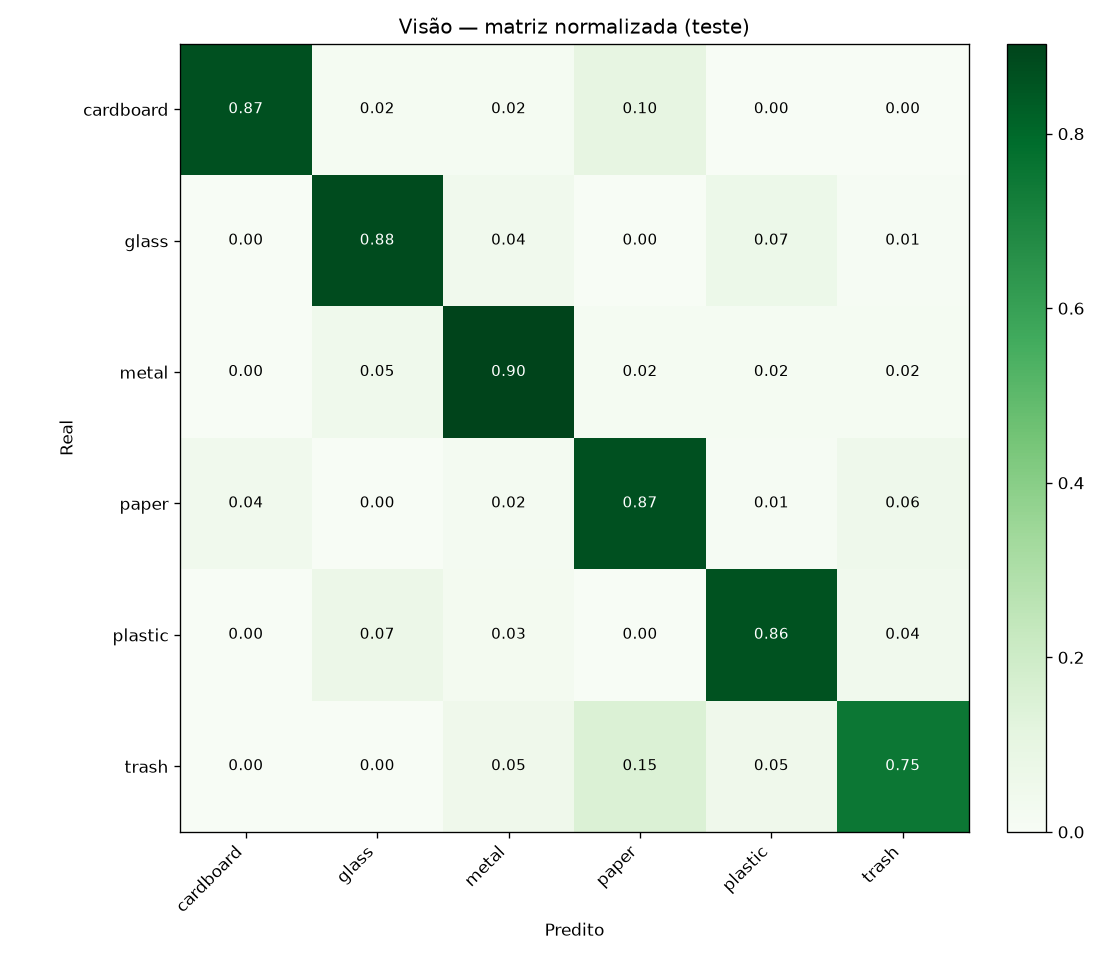

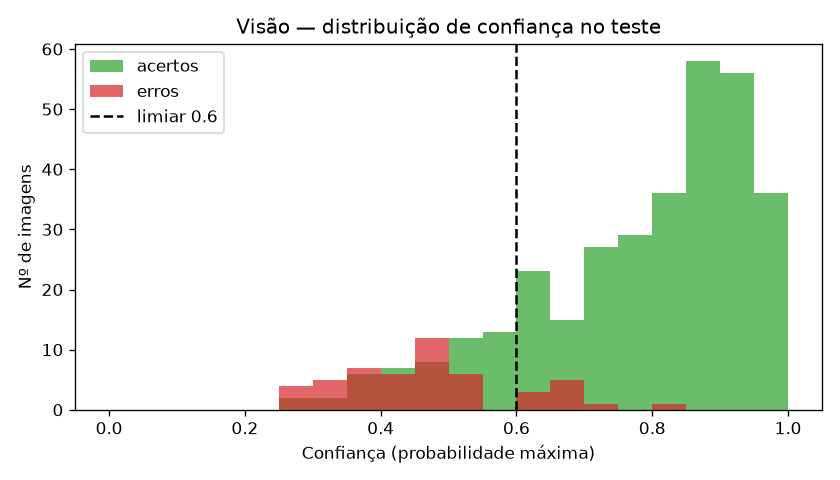

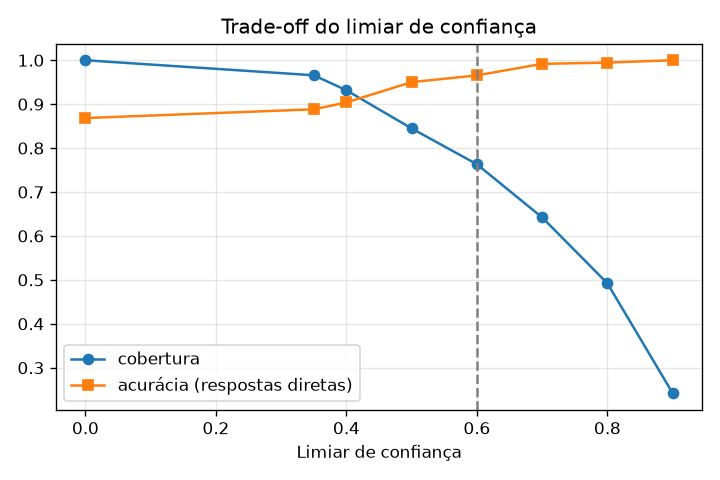

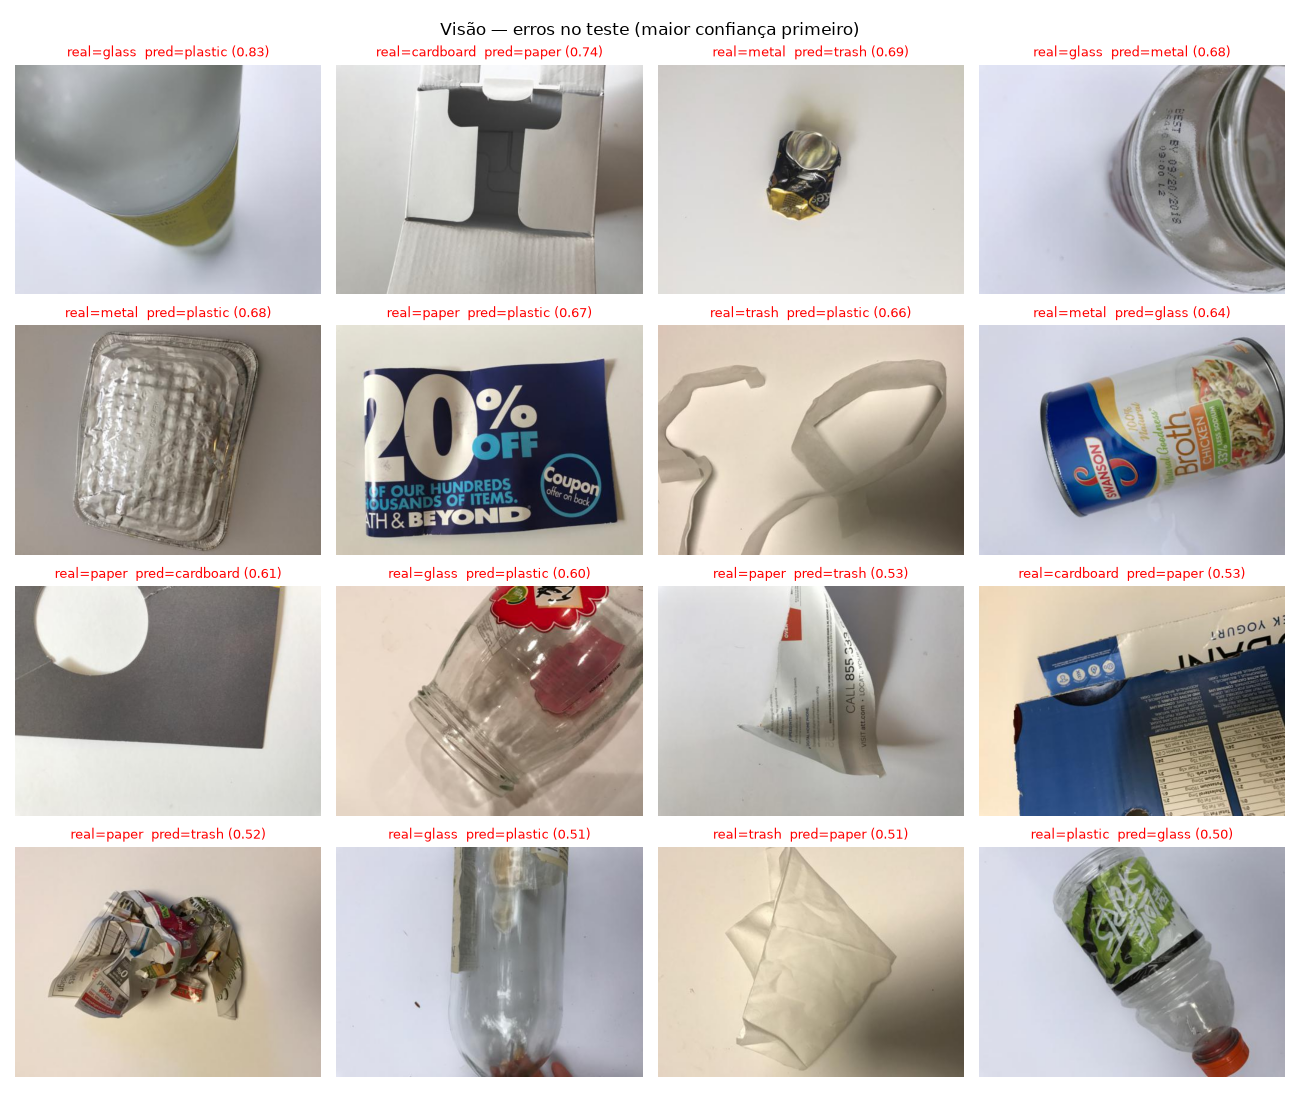

In [3]:
from IPython.display import Image, display
for g in ['visao_matriz_confusao_normalizada', 'visao_confianca_hist', 'limiar_cobertura', 'visao_erros_exemplos']:
    display(Image(f'resultados/graficos/{g}.png'))

## Comparação dos modelos de PLN

In [4]:
pd.read_csv('resultados/pln_comparacao_modelos.csv')

,modelo,hiperparametro,acuracia_teste,f1_macro_teste,cv5_acuracia,cv5_f1_macro
0,regressao_logistica,3.0,0.8431,0.8400,0.8328 ± 0.0466,0.8301 ± 0.0486
1,naive_bayes,0.5,0.7451,0.7365,0.7522 ± 0.0307,0.7320 ± 0.0378


## Fluxo integrado: Visão → PLN → Decisão

In [5]:
from src.pipeline import processar
r = processar('dados/exemplos/glass183.jpg', 'precisa lavar antes?')
print(r['visao']); print(r['pln']); print(r['decisao']['regra_id'], '-', r['decisao']['regra_descricao'])
print(); print(r['decisao']['resposta'])

{'classe': 'glass', 'confianca': 0.650245726108551, 'top2': [('glass', 0.650245726108551), ('paper', 0.19931115210056305)]}
{'intencao': 'preparo_antes', 'confianca': 0.9483283515161927}
R17 - SE classe=glass E intenção=preparo_antes E confiança>=0.60 ENTÃO resposta 'preparo_antes' para 'glass'

Antes de descartar **vidro**:
- Enxágue para retirar restos de bebida/alimento (não precisa ficar perfeito).
- Retire tampas metálicas ou plásticas e descarte-as em suas lixeiras (amarela/vermelha).
- Vidro quebrado: embrulhe em jornal ou coloque numa caixa e identifique 'VIDRO QUEBRADO' para proteger os coletores.


In [6]:
for pergunta in ['isso é reciclável?', 'onde posso levar?', 'qual a capital da frança?']:
    r = processar('dados/exemplos/metal174.jpg', pergunta)
    print(f"{pergunta!r:32} -> {r['pln']['intencao']:15} regra {r['decisao']['regra_id']}")

'isso é reciclável?'             -> e_reciclavel    regra R19
'onde posso levar?'              -> onde_levar      regra R20
'qual a capital da frança?'      -> fora_do_escopo  regra R01


## Exemplos salvos

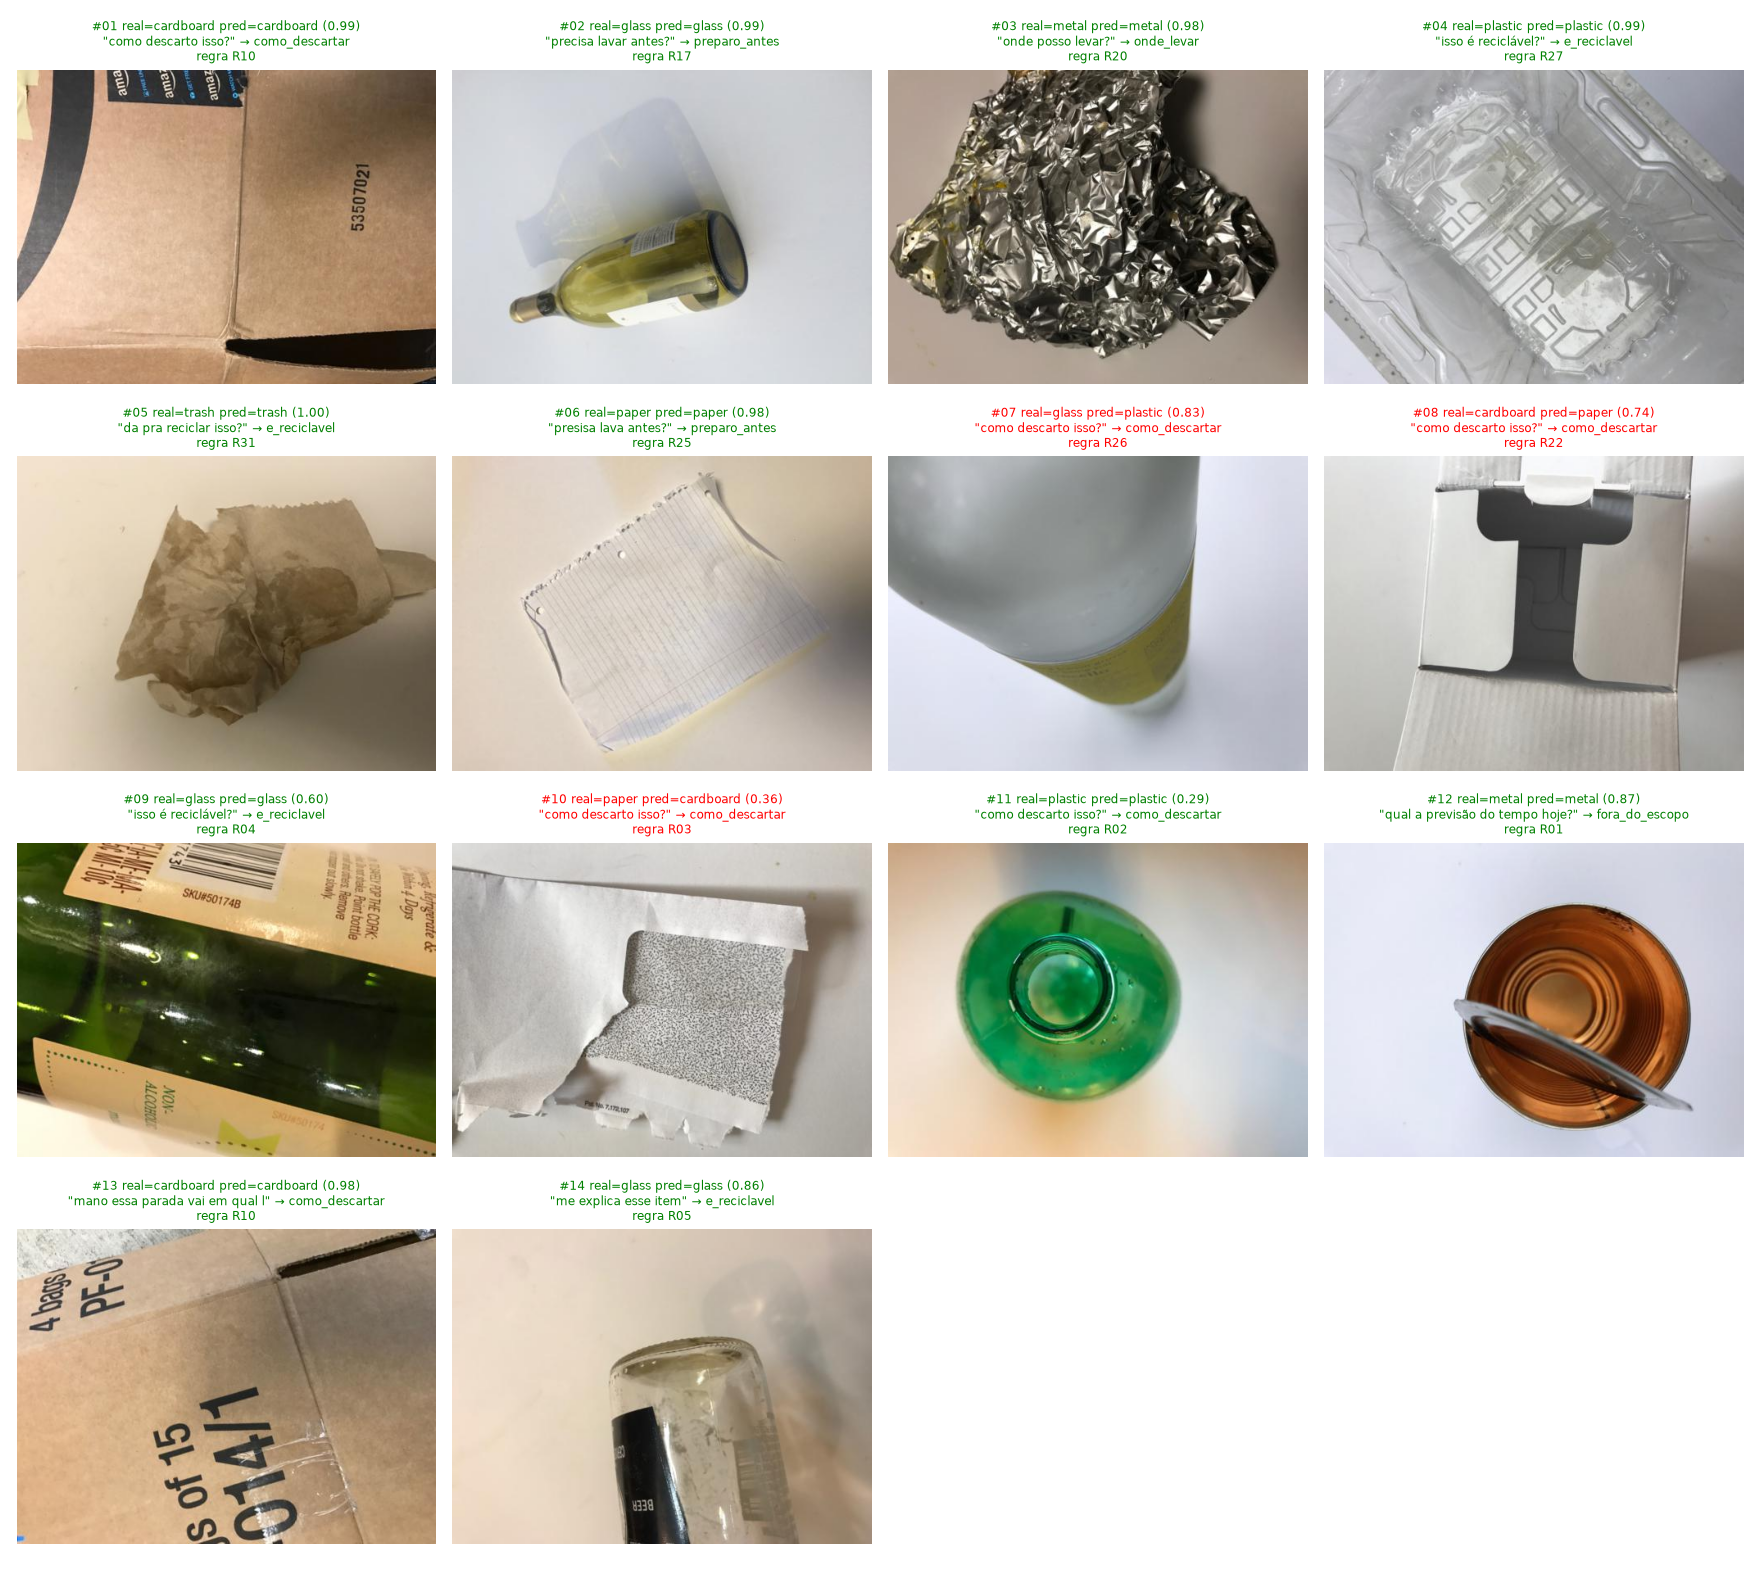

In [7]:
display(Image('resultados/exemplos/painel_exemplos.png'))